# Cooling coffee

A cup of filter coffee, a kitchen at 22 °C, and a thermometer read every two minutes. How long until it is pleasant to drink?

> **Try it.** Press `t` for the contents, `s` on any cell to save it as an image, `i` for what this notebook gives away, `/` to search, `?` for every key.

Newton's law of cooling says a cup loses heat in proportion to how much warmer it is than the room:

$$\frac{dT}{dt} = -k\,(T - T_{\text{room}})$$

In [1]:
%pip install -q tqdm

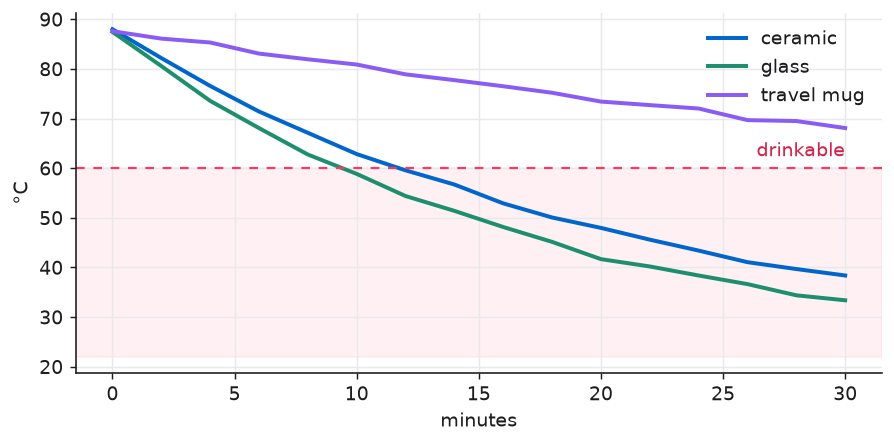

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

room = 22.0
minutes = np.arange(0, 32, 2)
rng = np.random.default_rng(7)

cups = {"ceramic": 0.047, "glass": 0.058, "travel mug": 0.012}
temp = {
    name: room + (88 - room) * np.exp(-k * minutes) + rng.normal(0, 0.4, minutes.size)
    for name, k in cups.items()
}

fig, ax = plt.subplots(figsize=(8, 3.6))
colours = {"ceramic": "#0066cc", "glass": "#1d8f6e", "travel mug": "#8a5cf5"}
for name, series in temp.items():
    ax.plot(minutes, series, lw=2.2, color=colours[name], label=name)
ax.axhspan(room, 60, color="#ff375f", alpha=0.07)
ax.axhline(60, color="#ff375f", lw=1.2, ls=(0, (4, 4)))
ax.text(30, 61.5, "drinkable", color="#d0224a", ha="right", va="bottom")
ax.set(xlabel="minutes", ylabel="°C")
ax.legend(frameon=False)

## The model

Solving the equation gives one number, $k$, for each cup:

$$\begin{align}
T(t) &= T_{\text{room}} + (T_0 - T_{\text{room}})\,e^{-kt} \\
t_{1/2} &= \frac{\ln 2}{k}
\end{align}$$

| Symbol | Meaning | Value |
|---|---|---|
| $T_0$ | Temperature when poured | 88 °C |
| $T_{\text{room}}$ | The kitchen | 22 °C |
| $k$ | How fast the cup gives up heat | fitted, per minute |

### Assumptions

- [x] The room stays at 22 °C
- [x] The coffee is stirred, so it has one temperature
- [ ] Evaporation matters (it does, a little; we ignore it)

## The data

Sixteen readings per cup, one every two minutes.

In [3]:
readings = pd.DataFrame({"minute": minutes, **{name: s.round(1) for name, s in temp.items()}})
readings

,minute,ceramic,glass,travel mug
0,0,88.0,87.5,87.6
1,2,82.2,80.6,86.1
2,4,76.6,73.6,85.3
3,6,71.4,68.1,83.1
4,8,67.1,62.8,81.9
5,10,62.9,58.9,80.9
6,12,59.6,54.4,78.9
7,14,56.7,51.4,77.7
8,16,52.9,48.2,76.5
9,18,50.1,45.2,75.2


### The same frame, as plain text

A `print` of a frame is not an HTML table, but the viewer reads the columns back into one.

In [4]:
print(readings.head(10))

   minute  ceramic  glass  travel mug
0       0     88.0   87.5        87.6
1       2     82.2   80.6        86.1
2       4     76.6   73.6        85.3
3       6     71.4   68.1        83.1
4       8     67.1   62.8        81.9
5      10     62.9   58.9        80.9
6      12     59.6   54.4        78.9
7      14     56.7   51.4        77.7
8      16     52.9   48.2        76.5
9      18     50.1   45.2        75.2


## Fitting k

Taking the log of the excess temperature turns the curve into a straight line, so a plain least squares fit is enough.

In [5]:
excess = np.log(readings["ceramic"] - room)
slope, intercept = np.polyfit(readings.minute, excess, 1)
k = -slope

print(f"k = {k:.4f} per minute")
print(f"half the excess heat is gone every {np.log(2) / k:.1f} minutes")

k = 0.0468 per minute
half the excess heat is gone every 14.8 minutes


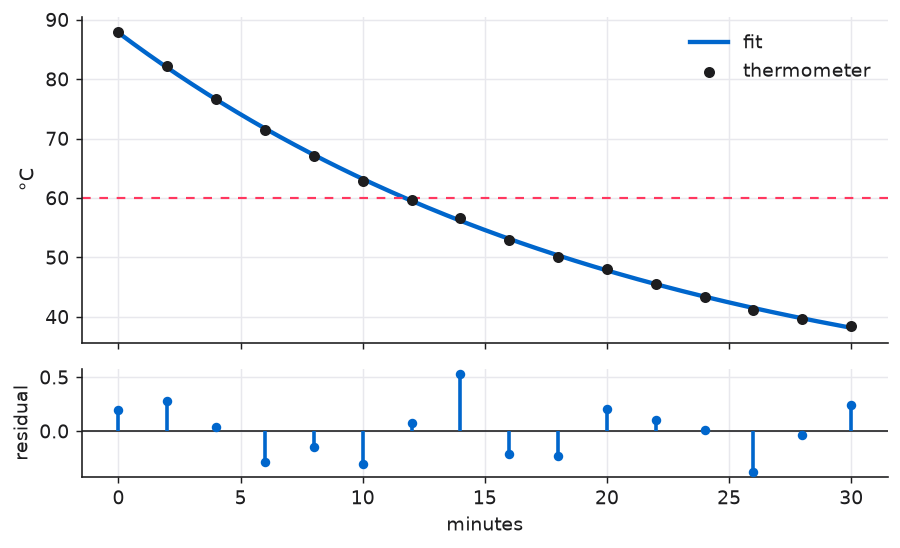

In [6]:
t = np.linspace(0, 30, 200)
fit = room + np.exp(intercept) * np.exp(-k * t)
residual = readings["ceramic"] - (room + np.exp(intercept) * np.exp(-k * readings.minute))

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 4.6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.12},
)
top.plot(t, fit, color="#0066cc", lw=2.4, label="fit")
top.scatter(readings.minute, readings["ceramic"], s=26, color="#1d1d1f", zorder=3, label="thermometer")
top.axhline(60, color="#ff375f", lw=1.2, ls=(0, (4, 4)))
top.set(ylabel="°C")
top.legend(frameon=False)

bottom.axhline(0, color="#1d1d1f", lw=0.9)
bottom.vlines(readings.minute, 0, residual, color="#0066cc", lw=2)
bottom.scatter(readings.minute, residual, s=18, color="#0066cc", zorder=3)
bottom.set(xlabel="minutes", ylabel="residual")

### How sure are we?

Refit on 200 random resamples of the readings. A progress bar like this one is stored frame by frame, and the viewer keeps only the last.

In [7]:
from tqdm import tqdm

ks = []
for _ in tqdm(range(200)):
    pick = rng.integers(0, minutes.size, minutes.size)
    s, _b = np.polyfit(minutes[pick], np.log(temp["ceramic"][pick] - room), 1)
    ks.append(-s)

lo, hi = np.percentile(ks, [2.5, 97.5])
print(f"k is between {lo:.4f} and {hi:.4f} (95%)")

100%|██████████| 200/200 [00:03<00:00, 61.35it/s]


k is between 0.0463 and 0.0474 (95%)


In [8]:
GREEN, AMBER, RESET = "\033[32m", "\033[33m", "\033[0m"

print(f"{GREEN}PASS{RESET}  residuals centred on zero (mean {residual.mean():+.2f} °C)")
print(f"{GREEN}PASS{RESET}  every reading below the pour temperature")
print(f"{AMBER}WARN{RESET}  thermometer resolution is 0.1 °C; the last readings sit close to the room")

PASS  residuals centred on zero (mean +0.00 °C)
PASS  every reading below the pour temperature
WARN  thermometer resolution is 0.1 °C; the last readings sit close to the room


In [9]:
for m in range(0, 31):
    print(f"t = {m:2d} min   {room + np.exp(intercept) * np.exp(-k * m):5.1f} °C")

t =  0 min    87.8 °C
t =  1 min    84.8 °C
t =  2 min    81.9 °C
t =  3 min    79.2 °C
t =  4 min    76.6 °C
t =  5 min    74.1 °C
t =  6 min    71.7 °C
t =  7 min    69.4 °C
t =  8 min    67.2 °C
t =  9 min    65.2 °C
t = 10 min    63.2 °C
t = 11 min    61.3 °C
t = 12 min    59.5 °C
t = 13 min    57.8 °C
t = 14 min    56.2 °C
t = 15 min    54.6 °C
t = 16 min    53.1 °C
t = 17 min    51.7 °C
t = 18 min    50.3 °C
t = 19 min    49.0 °C
t = 20 min    47.8 °C
t = 21 min    46.6 °C
t = 22 min    45.5 °C
t = 23 min    44.4 °C
t = 24 min    43.4 °C
t = 25 min    42.4 °C
t = 26 min    41.5 °C
t = 27 min    40.6 °C
t = 28 min    39.7 °C
t = 29 min    38.9 °C
t = 30 min    38.2 °C


## What the fit says

The cup cools fastest while it is hottest. The gap to the room shrinks by the same fraction every minute, so the first ten minutes decide most of the story.

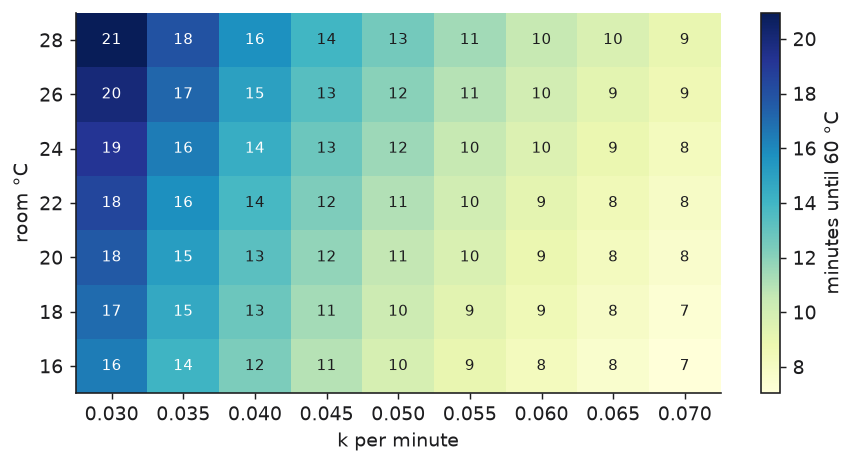

In [10]:
ks_grid = np.linspace(0.03, 0.07, 9)
rooms = np.linspace(16, 28, 7)
wait = np.array([[np.log((88 - r) / (60 - r)) / kk for kk in ks_grid] for r in rooms])

fig, ax = plt.subplots(figsize=(8, 3.8))
image = ax.imshow(wait, cmap="YlGnBu", aspect="auto", origin="lower")
ax.set_xticks(range(len(ks_grid)), [f"{v:.3f}" for v in ks_grid])
ax.set_yticks(range(len(rooms)), [f"{v:.0f}" for v in rooms])
ax.set(xlabel="k per minute", ylabel="room °C")
ax.grid(False)
for i in range(len(rooms)):
    for j in range(len(ks_grid)):
        ax.text(j, i, f"{wait[i, j]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if wait[i, j] > 14 else "#1d1d1f")
fig.colorbar(image, label="minutes until 60 °C")

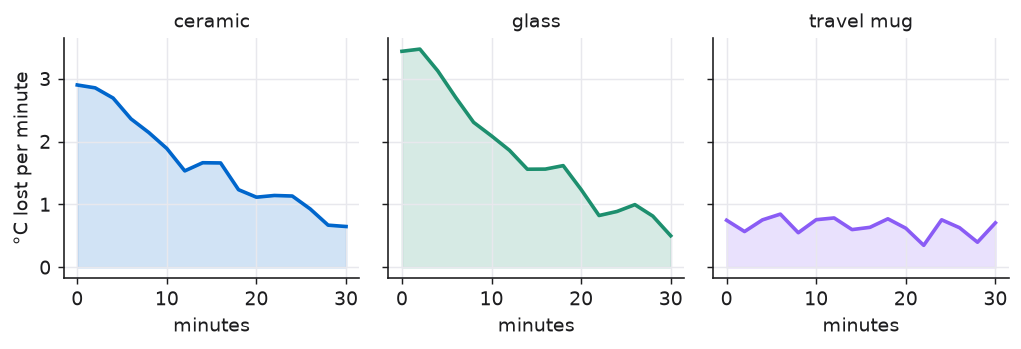

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(8, 2.8), sharey=True)
for ax, (name, series) in zip(axes, temp.items()):
    rate = -np.gradient(series, minutes)
    ax.fill_between(minutes, rate, color=colours[name], alpha=0.18)
    ax.plot(minutes, rate, color=colours[name], lw=2)
    ax.set_title(name, fontsize=10.5)
    ax.set_xlabel("minutes")
axes[0].set_ylabel("°C lost per minute")
fig.tight_layout()

## When to drink

Most people stop flinching at 60 °C.

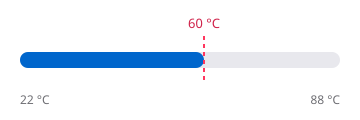

In [12]:
from IPython.display import SVG, Markdown

drinkable = np.log((88 - room) / (60 - room)) / k
SVG(f'''<svg xmlns="http://www.w3.org/2000/svg" width="360" height="120" viewBox="0 0 360 120" role="img" aria-label="A thermometer marked at 60 degrees">
  <rect x="20" y="52" width="320" height="16" rx="8" fill="#e8e8ed"/>
  <rect x="20" y="52" width="{320 * (60 - room) / (88 - room):.0f}" height="16" rx="8" fill="#0066cc"/>
  <line x1="{20 + 320 * (60 - room) / (88 - room):.0f}" y1="36" x2="{20 + 320 * (60 - room) / (88 - room):.0f}" y2="84" stroke="#ff375f" stroke-width="2" stroke-dasharray="4 4"/>
  <text x="{20 + 320 * (60 - room) / (88 - room):.0f}" y="28" text-anchor="middle" font-family="system-ui, sans-serif" font-size="13" fill="#d0224a">60 °C</text>
  <text x="20" y="104" font-family="system-ui, sans-serif" font-size="12" fill="#6e6e73">{room:.0f} °C</text>
  <text x="340" y="104" text-anchor="end" font-family="system-ui, sans-serif" font-size="12" fill="#6e6e73">88 °C</text>
</svg>''')

In [13]:
Markdown(f"**Drinkable after {drinkable:.1f} minutes.** A travel mug would take about {np.log((88 - room) / (60 - room)) / 0.012:.0f}.")

**Drinkable after 11.8 minutes.** A travel mug would take about 46.

In [14]:
readings["temp"]

KeyError: 'temp'

## Edit it

This notebook is editable, text and all. Double-click any paragraph, heading or list, press `e`, or use the pencil at the top right, and write. A bar opens with undo, bold, italic, code, link, headings and lists. Once one block is open, a click on any other text moves the editor there, and `↑` `↓` carry on into the next cell. `Esc` finishes.

Code and outputs are never touched, and nothing runs. Saving changes only the text you edited, so every figure and table above stays as it is.

| You opened it from | Save |
|---|---|
| A file, in Chromium | Writes into that file |
| A link, like this demo | Saves a copy to your computer |
| Safari or Firefox | Downloads the edited notebook |

Try it: change this sentence, then press `⌘S`. This demo has no file to write to, so it saves a copy.

## Before you share this

Press `i`. The sheet lists what a notebook gives away without its author noticing: a key pasted into a cell, a home folder in a traceback. It also lists what the notebook needs to run and what makes it heavy, and it can make a link with the notebook inside it.

Everything here is made up, including the token below.

To run the same fit from a shell, or against a table of readings:

```bash
pip install numpy pandas matplotlib tqdm
jupyter lab cooling-coffee.ipynb
```

```sql
SELECT cup, MIN(minute) AS minutes_to_drinkable
FROM readings
WHERE temp_c <= 60
GROUP BY cup;
```

In [15]:
SCALE_API_TOKEN = "demo-9f3a71c2e8d4b605"  # not a real key; the sheet flags it anyway
print("Scale token set:", SCALE_API_TOKEN[:5] + "…")

Scale token set: demo-…
